# 01 - Data Exploration

This notebook is the starting point for exploring the Online Retail II dataset (UCI Machine Learning Repository) for the E-Commerce Analytics Dashboard project.

In [1]:
import pandas as pd
from pathlib import Path

# Find the project folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Dataset location
file_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

# Read the Excel dataset
df = pd.read_excel(file_path, sheet_name=0)

# Display the first five rows
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

Dataset shape: (525461, 8)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [4]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

# Calculate missing value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing values percentage:")
print(missing_percentage.round(2))

# Check duplicate rows
duplicates = df.duplicated().sum()

print("\nNumber of duplicate rows:", duplicates)

Missing values per column:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Missing values percentage:
Invoice         0.00
StockCode       0.00
Description     0.56
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    20.54
Country         0.00
dtype: float64

Number of duplicate rows: 6865


In [5]:
# Check cancelled invoices
cancelled = df["Invoice"].astype(str).str.startswith("C")

print("Cancelled transaction rows:", cancelled.sum())

# Check negative quantities
negative_qty = (df["Quantity"] < 0).sum()

print("Negative quantities:", negative_qty)

# Check zero or negative prices
invalid_prices = (df["Price"] <= 0).sum()

print("Zero or negative prices:", invalid_prices)

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Cancelled transaction rows: 10206
Negative quantities: 12326
Zero or negative prices: 3690
Duplicate rows: 6865


In [6]:
# Identify cancelled invoices
is_cancelled = df["Invoice"].astype(str).str.startswith("C")

# Identify negative quantities
is_negative = df["Quantity"] < 0

# Compare cancelled invoices and negative quantities
print("Cancelled invoices with negative quantity:",
      (is_cancelled & is_negative).sum())

print("Negative quantities without cancelled invoice:",
      (~is_cancelled & is_negative).sum())

print("Cancelled invoices without negative quantity:",
      (is_cancelled & ~is_negative).sum())

# Display examples
df.loc[~is_cancelled & is_negative].head(10)

Cancelled invoices with negative quantity: 10205
Negative quantities without cancelled invoice: 2121
Cancelled invoices without negative quantity: 1


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


In [7]:
# Create a copy of the original dataset
sales_df = df.copy()

# Keep only valid sales transactions
sales_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["Price"] > 0) &
    (~sales_df["Invoice"].astype(str).str.startswith("C"))
].copy()

# Compare original and filtered datasets
print("Original dataset:", len(df))
print("Sales dataset:", len(sales_df))
print("Excluded rows:", len(df) - len(sales_df))

# Display the first five rows
sales_df.head()

Original dataset: 525461
Sales dataset: 511565
Excluded rows: 13896


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
# Check missing values after filtering
print("Missing values in sales dataset:")
print(sales_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(sales_df.duplicated().sum())

# Check dataset dimensions
print("\nSales dataset shape:")
print(sales_df.shape)

Missing values in sales dataset:
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    103901
Country             0
dtype: int64

Duplicate rows:
6835

Sales dataset shape:
(511565, 8)


In [9]:
# Find all rows that belong to duplicate groups
duplicate_rows = sales_df[
    sales_df.duplicated(keep=False)
]

# Sort duplicates by invoice and stock code
duplicate_rows = duplicate_rows.sort_values(
    by=["Invoice", "StockCode"]
)

print("Rows belonging to duplicate groups:", len(duplicate_rows))

# Display examples
duplicate_rows.head(10)

Rows belonging to duplicate groups: 13224


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [10]:
# Calculate revenue for each sales row
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["Price"]

# Calculate revenue keeping all rows
revenue_with_duplicates = sales_df["Revenue"].sum()

# Calculate revenue after removing exact duplicates
sales_without_duplicates = sales_df.drop_duplicates(
    subset=df.columns.tolist()
)

revenue_without_duplicates = sales_without_duplicates["Revenue"].sum()

# Compare the results
print("Revenue with duplicates:", round(revenue_with_duplicates, 2))
print("Revenue without duplicates:", round(revenue_without_duplicates, 2))

difference = revenue_with_duplicates - revenue_without_duplicates

print("Revenue difference:", round(difference, 2))
print("Percentage difference:",
      round(difference / revenue_with_duplicates * 100, 2), "%")

Revenue with duplicates: 10305892.02
Revenue without duplicates: 10271762.66
Revenue difference: 34129.36
Percentage difference: 0.33 %


In [11]:
# Create a copy of the cleaned sales data
sales_clean = sales_df.copy()

# Rename columns for easier SQL usage
sales_clean = sales_clean.rename(columns={
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country",
    "Revenue": "revenue"
})

# Display the first five rows
sales_clean.head()

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [12]:
print("Dataset shape:", sales_clean.shape)

print("\nColumn names:")
print(sales_clean.columns.tolist())

print("\nMissing values:")
print(sales_clean.isnull().sum())

print("\nTotal revenue:")
print(round(sales_clean["revenue"].sum(), 2))

Dataset shape: (511565, 9)

Column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'revenue']

Missing values:
invoice              0
stock_code           0
description          0
quantity             0
invoice_date         0
price                0
customer_id     103901
country              0
revenue              0
dtype: int64

Total revenue:
10305892.02


In [13]:
# Define the output file location
output_path = project_root / "data" / "processed" / "sales_clean.csv"

# Save the cleaned dataset
sales_clean.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path)

Dataset saved successfully!
File location: c:\Users\PULSE Electronics\OneDrive\Documents\Projects\ecommerce-analytics-dashboard\data\processed\sales_clean.csv


In [14]:
# Data Quality Validation - Duplicate Analysis

duplicate_rows = sales_df[
    sales_df.duplicated(keep=False)
]

print("Total sales rows:", len(sales_df))
print("Rows in duplicate groups:", len(duplicate_rows))
print("Extra duplicate rows:", sales_df.duplicated().sum())

print("\nRevenue with duplicates:")
print(round(sales_df["revenue"].sum(), 2))

print("\nRevenue without duplicates:")
print(round(
    sales_df.drop_duplicates()["revenue"].sum(), 2
))

Total sales rows: 511565
Rows in duplicate groups: 13224
Extra duplicate rows: 6835

Revenue with duplicates:


KeyError: 'revenue'

In [15]:
# Add revenue column if it does not exist
if "revenue" not in sales_df.columns:
    sales_df["revenue"] = (
        sales_df["Quantity"] * sales_df["Price"]
    )

print("Revenue column created successfully!")
print(sales_df.columns.tolist())

Revenue column created successfully!
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue', 'revenue']


In [16]:
# Duplicate revenue impact analysis

revenue_with_duplicates = sales_df["revenue"].sum()

revenue_without_duplicates = (
    sales_df.drop_duplicates()["revenue"].sum()
)

difference = (
    revenue_with_duplicates - revenue_without_duplicates
)

percentage = (
    difference / revenue_with_duplicates
) * 100

print("Revenue with duplicates:", round(revenue_with_duplicates, 2))
print("Revenue without duplicates:", round(revenue_without_duplicates, 2))
print("Revenue difference:", round(difference, 2))
print("Percentage difference:", round(percentage, 2), "%")

Revenue with duplicates: 10305892.02
Revenue without duplicates: 10271762.66
Revenue difference: 34129.36
Percentage difference: 0.33 %


In [17]:
# Special transaction analysis

special_codes = ["M", "POST", "DOT"]

special_transactions = sales_df[
    sales_df["StockCode"].astype(str).isin(special_codes)
].copy()

special_summary = (
    special_transactions
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        transactions=("Invoice", "count"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

print("Special transaction summary:")
display(special_summary)

print("\nTotal special transaction revenue:")
print(round(special_transactions["revenue"].sum(), 2))

Special transaction summary:


,StockCode,Description,transactions,total_revenue
1,M,Manual,555,262606.01
0,DOT,DOTCOM POSTAGE,730,116408.71
2,POST,POSTAGE,759,49477.54



Total special transaction revenue:
428492.26


In [18]:
# Identify other potential non-product stock codes

code_summary = (
    sales_df
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        rows=("Invoice", "count"),
        total_revenue=("revenue", "sum")
    )
    .reset_index()
)

special_pattern = r"POSTAGE|MANUAL|DISCOUNT|ADJUST|BANK CHARGE|CARRIAGE|AMAZON FEE"

potential_non_products = code_summary[
    code_summary["Description"]
    .fillna("")
    .str.contains(special_pattern, case=False, regex=True)
]

display(
    potential_non_products.sort_values(
        "total_revenue", ascending=False
    ).head(30)
)

,StockCode,Description,rows,total_revenue
4717,M,Manual,555,262606.01
4716,DOT,DOTCOM POSTAGE,730,116408.71
4719,POST,POSTAGE,759,49477.54
4695,AMAZONFEE,AMAZON FEE,2,20248.04
4698,C2,CARRIAGE,131,6625.00
4693,ADJUST,Adjustment by john on 26/01/2010 17,16,6563.50
4692,ADJUST,Adjustment by john on 26/01/2010 16,20,2334.43
4694,ADJUST2,Adjustment by Peter on Jun 25 2010,3,731.05
4699,D,Discount,5,397.89
4697,BANK CHARGES,Bank Charges,21,339.24


In [19]:
# Classify product and non-product transactions

special_codes = [
    "M", "DOT", "POST", "AMAZONFEE",
    "C2", "ADJUST", "ADJUST2",
    "D", "BANK CHARGES"
]

sales_df["transaction_type"] = (
    sales_df["StockCode"]
    .astype(str)
    .str.strip()
    .str.upper()
    .apply(
        lambda code: "Non-product"
        if code in special_codes
        else "Product"
    )
)

print("Transaction classification:")
print(sales_df["transaction_type"].value_counts())

print("\nRevenue by transaction type:")
print(
    sales_df.groupby("transaction_type")["revenue"].sum()
)

Transaction classification:
transaction_type
Product        509317
Non-product      2248
Name: count, dtype: int64

Revenue by transaction type:
transaction_type
Non-product     465773.910
Product        9840118.114
Name: revenue, dtype: float64


In [20]:
# Create product-only dataset

products_df = sales_df[
    sales_df["transaction_type"] == "Product"
].copy()

print("Total rows:", len(sales_df))
print("Product rows:", len(products_df))

print(
    "Product revenue:",
    round(products_df["revenue"].sum(), 2)
)

Total rows: 511565
Product rows: 509317
Product revenue: 9840118.11


In [35]:
# Analyze cancellations and returns

# Identify cancelled invoices
cancelled_invoices = sales_df[
    sales_df["Invoice"].astype(str).str.upper().str.startswith("C")
]

# Identify negative quantities
negative_quantity = sales_df[
    sales_df["Quantity"] < 0
]

# Identify negative prices
negative_price = sales_df[
    sales_df["Price"] < 0
]

print("Cancelled invoice rows:", len(cancelled_invoices))
print("Negative quantity rows:", len(negative_quantity))
print("Negative price rows:", len(negative_price))

print("\nRevenue from negative quantities:")
print(round(negative_quantity["revenue"].sum(), 2))

print("\nSample cancelled transactions:")
display(cancelled_invoices.head(10))

Cancelled invoice rows: 0
Negative quantity rows: 0
Negative price rows: 0

Revenue from negative quantities:
0.0

Sample cancelled transactions:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,revenue,transaction_type


In [21]:
# Final data quality summary

print("DATA QUALITY SUMMARY")
print("-" * 40)

print("Total rows:", len(sales_df))
print("Product rows:", len(products_df))

print("\nTransaction types:")
print(sales_df["transaction_type"].value_counts())

print("\nMissing values:")
print(sales_df.isnull().sum())

print("\nDuplicate rows:")
print(sales_df.duplicated().sum())

print("\nTotal revenue:")
print(round(sales_df["revenue"].sum(), 2))

print("\nProduct revenue:")
print(round(products_df["revenue"].sum(), 2))

DATA QUALITY SUMMARY
----------------------------------------
Total rows: 511565
Product rows: 509317

Transaction types:
transaction_type
Product        509317
Non-product      2248
Name: count, dtype: int64

Missing values:
Invoice                  0
StockCode                0
Description              0
Quantity                 0
InvoiceDate              0
Price                    0
Customer ID         103901
Country                  0
Revenue                  0
revenue                  0
transaction_type         0
dtype: int64

Duplicate rows:
6835

Total revenue:
10305892.02

Product revenue:
9840118.11


In [22]:
# Create a standardized analysis dataset

analysis_df = sales_df.copy()

# Standardize column names
analysis_df.columns = (
    analysis_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Remove duplicated revenue column names
analysis_df = analysis_df.loc[
    :, ~analysis_df.columns.duplicated()
].copy()

print("Dataset shape:", analysis_df.shape)

print("\nColumns:")
print(analysis_df.columns.tolist())

print("\nFirst 5 rows:")
display(analysis_df.head())

Dataset shape: (511565, 10)

Columns:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'revenue', 'transaction_type']

First 5 rows:


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,revenue,transaction_type
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,Product
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,Product
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,Product
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,Product
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,Product


In [23]:
# Standardize column names

analysis_df = analysis_df.rename(columns={
    "stockcode": "stock_code",
    "invoicedate": "invoice_date"
})

print("Final column names:")
print(analysis_df.columns.tolist())

Final column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'revenue', 'transaction_type']


In [24]:
# Verify revenue consistency

revenue_match = (
    (sales_df["Revenue"] - sales_df["revenue"])
    .abs()
    .lt(0.000001)
    .all()
)

print("Revenue columns match:", revenue_match)

print("Remaining duplicate rows:",
      analysis_df.duplicated().sum())

print("Missing customer IDs:",
      analysis_df["customer_id"].isna().sum())

Revenue columns match: True
Remaining duplicate rows: 6835
Missing customer IDs: 103901


In [25]:
# Save standardized analysis dataset

from pathlib import Path

output_path = Path("../data/processed/sales_analysis.csv")

analysis_df.to_csv(
    output_path,
    index=False
)

print("Dataset saved successfully!")
print("File location:", output_path.resolve())
print("Rows saved:", len(analysis_df))
print("Columns saved:", len(analysis_df.columns))

Dataset saved successfully!
File location: C:\Users\PULSE Electronics\OneDrive\Documents\Projects\ecommerce-analytics-dashboard\data\processed\sales_analysis.csv
Rows saved: 511565
Columns saved: 10


Product revenue statistics:
count    509317.000000
mean         19.320223
std          65.402071
min           0.001000
25%           4.200000
50%          10.120000
75%          17.700000
max       15818.400000
Name: revenue, dtype: float64


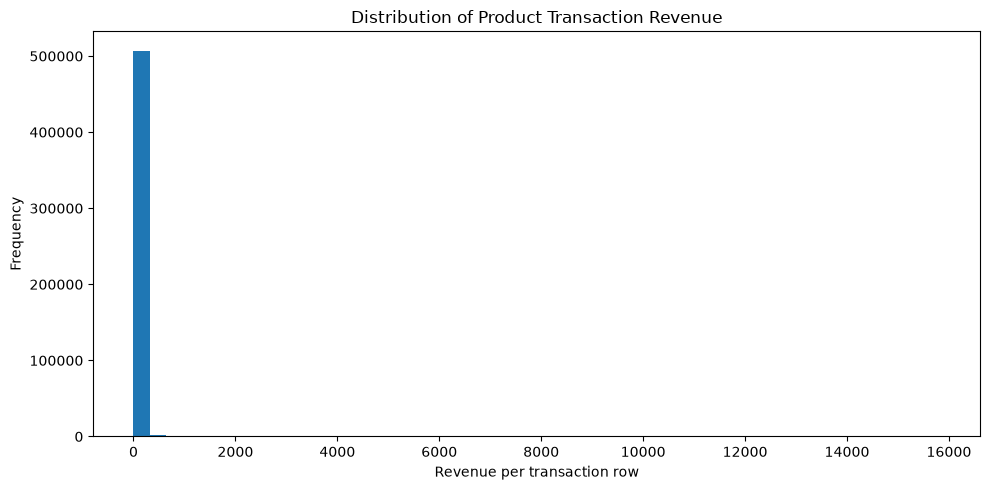

In [26]:
# Revenue distribution analysis

import matplotlib.pyplot as plt

product_revenue = analysis_df.loc[
    analysis_df["transaction_type"] == "Product",
    "revenue"
]

print("Product revenue statistics:")
print(product_revenue.describe())

plt.figure(figsize=(10, 5))

plt.hist(
    product_revenue,
    bins=50
)

plt.title("Distribution of Product Transaction Revenue")
plt.xlabel("Revenue per transaction row")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

99th percentile: 175.2


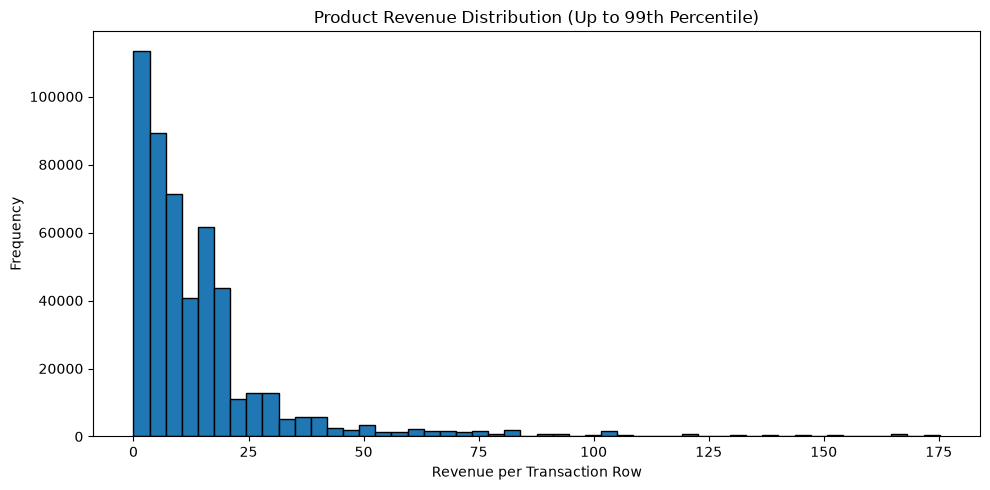

In [27]:
# Revenue distribution excluding extreme values from visualization

p99 = product_revenue.quantile(0.99)

print("99th percentile:", round(p99, 2))

filtered_revenue = product_revenue[
    product_revenue <= p99
]

plt.figure(figsize=(10, 5))

plt.hist(
    filtered_revenue,
    bins=50,
    edgecolor="black"
)

plt.title("Product Revenue Distribution (Up to 99th Percentile)")
plt.xlabel("Revenue per Transaction Row")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [28]:
# Outlier analysis using the 99th percentile

p99 = product_revenue.quantile(0.99)

outliers_df = analysis_df[
    (analysis_df["transaction_type"] == "Product") &
    (analysis_df["revenue"] > p99)
].copy()

print("99th percentile:", round(p99, 2))

print("Number of outlier rows:", len(outliers_df))

print(
    "Total outlier revenue:",
    round(outliers_df["revenue"].sum(), 2)
)

outlier_percentage = (
    outliers_df["revenue"].sum()
    / product_revenue.sum()
) * 100

print(
    "Percentage of product revenue from outliers:",
    round(outlier_percentage, 2),
    "%"
)

print("\nTop 10 highest-revenue transaction rows:")

display(
    outliers_df.sort_values(
        by="revenue",
        ascending=False
    ).head(10)
)

99th percentile: 175.2
Number of outlier rows: 5093
Total outlier revenue: 2153076.13
Percentage of product revenue from outliers: 21.88 %

Top 10 highest-revenue transaction rows:


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,revenue,transaction_type
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838.0,United Kingdom,15818.40,Product
228042,511465,15044A,PINK PAPER PARASOL,3500,2010-06-08 12:59:00,2.55,18008.0,United Kingdom,8925.00,Product
461644,533027,22086,PAPER CHAIN KIT 50'S CHRISTMAS,835,2010-11-15 16:02:00,6.95,NaN,United Kingdom,5803.25,Product
379875,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,2010-10-08 10:10:00,1.66,15838.0,United Kingdom,5179.20,Product
358821,524181,21622,VINTAGE UNION JACK CUSHION COVER,648,2010-09-27 16:59:00,6.89,17450.0,United Kingdom,4464.72,Product
452200,532358,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,2010-11-11 17:05:00,1.45,12931.0,United Kingdom,4176.00,Product
420628,529613,22423,REGENCY CAKESTAND 3 TIER,360,2010-10-29 10:46:00,10.95,17949.0,United Kingdom,3942.00,Product
390762,526934,22790,"MIRROR, ARCHED GEORGIAN",200,2010-10-14 09:46:00,19.42,18102.0,United Kingdom,3884.00,Product
358823,524181,21624,VINTAGE UNION JACK DOORSTOP,648,2010-09-27 16:59:00,5.96,17450.0,United Kingdom,3862.08,Product
519376,537659,21623,VINTAGE UNION JACK MEMOBOARD,600,2010-12-07 16:43:00,6.38,18102.0,United Kingdom,3828.00,Product


In [29]:
# Monthly product revenue analysis

monthly_revenue = (
    analysis_df[
        analysis_df["transaction_type"] == "Product"
    ]
    .assign(
        month=lambda df: df["invoice_date"].dt.to_period("M")
    )
    .groupby("month")["revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["month"] = (
    monthly_revenue["month"].dt.to_timestamp()
)

display(monthly_revenue)

,month,revenue
0,2009-12-01,801433.840
1,2010-01-01,614008.892
2,2010-02-01,539761.706
3,2010-03-01,764376.401
4,2010-04-01,649200.752
5,2010-05-01,645739.000
6,2010-06-01,699384.100
7,2010-07-01,634982.090
8,2010-08-01,676215.890
9,2010-09-01,871912.381


In [30]:
# Check dataset date coverage

print("First transaction:",
      analysis_df["invoice_date"].min())

print("Last transaction:",
      analysis_df["invoice_date"].max())

print("Total months:",
      analysis_df["invoice_date"].dt.to_period("M").nunique())

First transaction: 2009-12-01 07:45:00
Last transaction: 2010-12-09 20:01:00
Total months: 13


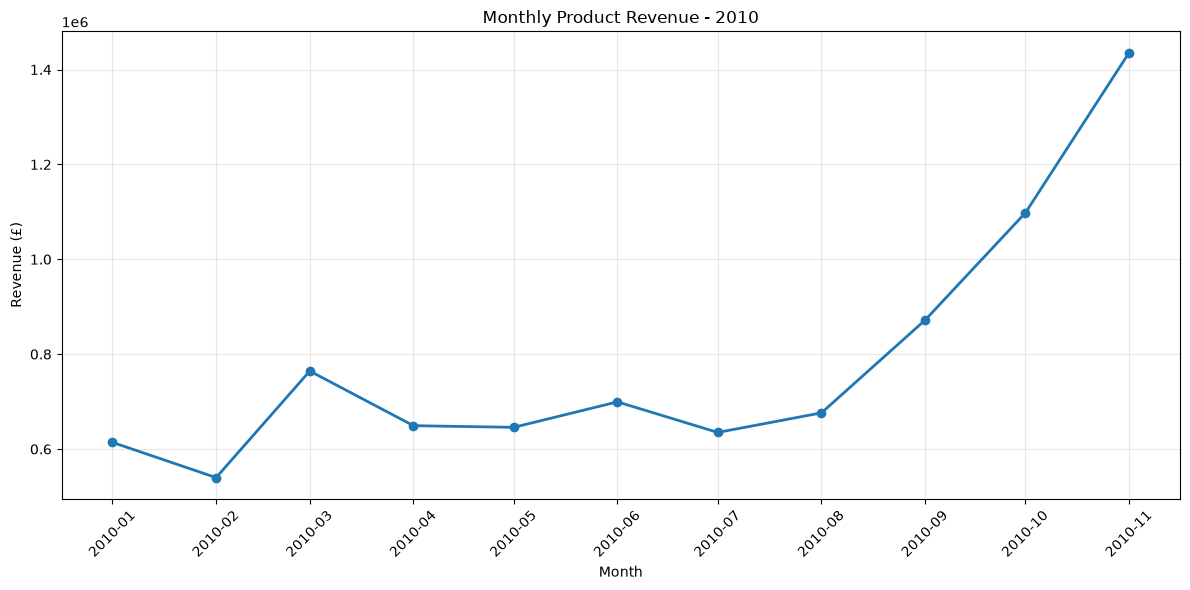

In [31]:
import matplotlib.pyplot as plt

# Keep only complete calendar months
monthly_complete = monthly_revenue[
    (monthly_revenue["month"] >= "2010-01-01") &
    (monthly_revenue["month"] < "2010-12-01")
].copy()

# Create the chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_complete["month"],
    monthly_complete["revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Product Revenue - 2010")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

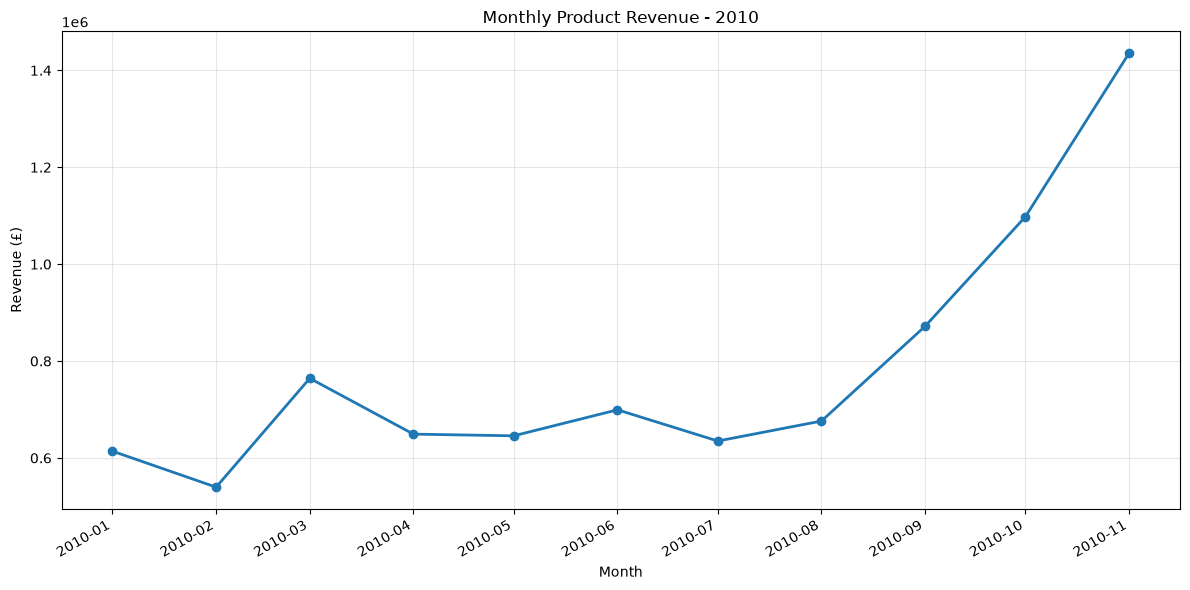

Chart saved successfully!


In [32]:
from pathlib import Path

# Project images folder
images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

# Save chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_complete["month"],
    monthly_complete["revenue"],
    marker="o",
    linewidth=2
)

ax.set_title("Monthly Product Revenue - 2010")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    images_dir / "monthly_product_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

In [33]:
# Top 10 products by revenue

top_products = (
    analysis_df[
        analysis_df["transaction_type"] == "Product"
    ]
    .groupby(["stock_code", "description"])
    .agg(
        total_revenue=("revenue", "sum"),
        units_sold=("quantity", "sum")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

display(top_products)

,stock_code,description,total_revenue,units_sold
1731,22423,REGENCY CAKESTAND 3 TIER,170078.51,13698
4271,85123A,WHITE HANGING HEART T-LIGHT HOLDER,158590.87,58487
2892,84879,ASSORTED COLOUR BIRD ORNAMENT,73092.99,45348
1330,22086,PAPER CHAIN KIT 50'S CHRISTMAS,58189.25,17226
4254,85099B,JUMBO BAG RED RETROSPOT,54483.87,30386
2556,47566,PARTY BUNTING,49682.72,10083
2738,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,47985.09,23049
3169,15056N,EDWARDIAN PARASOL NATURAL,36251.10,7416
920,21621,VINTAGE UNION JACK BUNTING,36125.71,4156
4258,85099F,JUMBO BAG STRAWBERRY,35918.34,19851


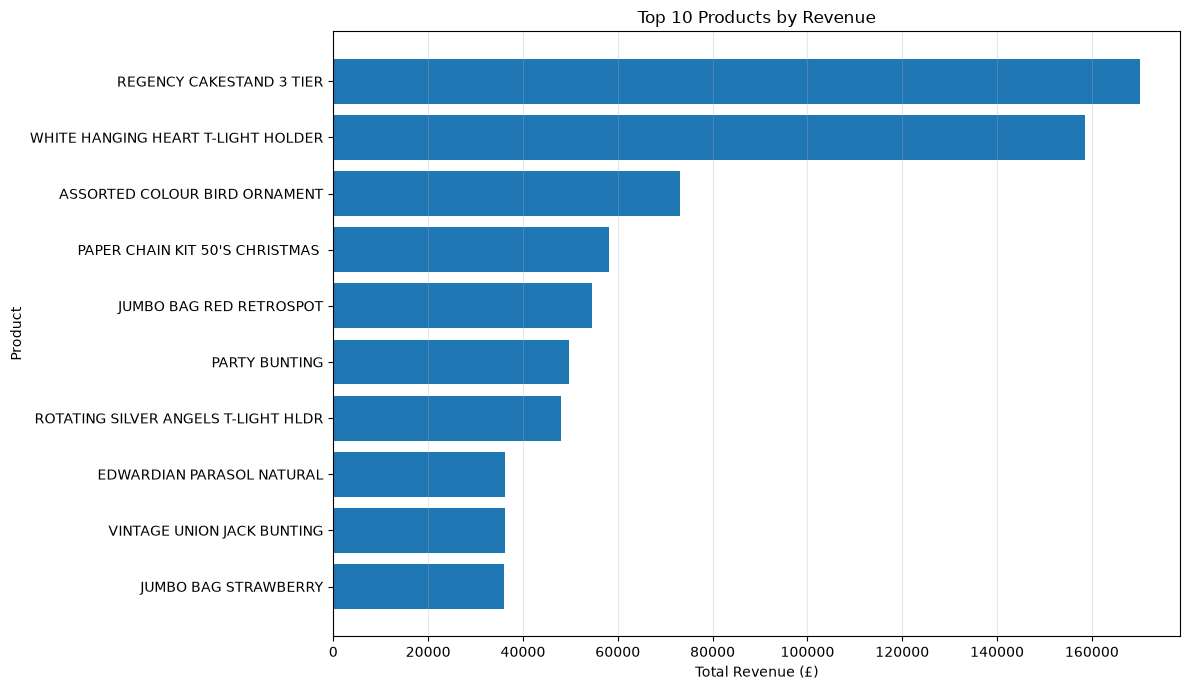

In [34]:
# Top 10 Products by Revenue Visualization

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_products["description"],
    top_products["total_revenue"]
)

ax.invert_yaxis()

ax.set_title("Top 10 Products by Revenue")
ax.set_xlabel("Total Revenue (£)")
ax.set_ylabel("Product")

ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

plt.show()

In [35]:
fig.savefig(
    images_dir / "top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

print("Top 10 products chart saved successfully!")

Top 10 products chart saved successfully!


In [36]:
# Revenue by Country

country_revenue = (
    analysis_df[
        analysis_df["transaction_type"] == "Product"
    ]
    .groupby("country")
    .agg(
        total_revenue=("revenue", "sum"),
        total_orders=("invoice", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(country_revenue.head(10))

,country,total_revenue,total_orders
37,United Kingdom,8487709.803,19064
10,EIRE,357764.330,309
24,Netherlands,266063.320,124
13,Germany,183259.861,325
12,France,132366.060,227
9,Denmark,50348.850,25
32,Sweden,49513.710,65
31,Spain,42887.680,58
33,Switzerland,41182.390,36
0,Australia,30313.350,35


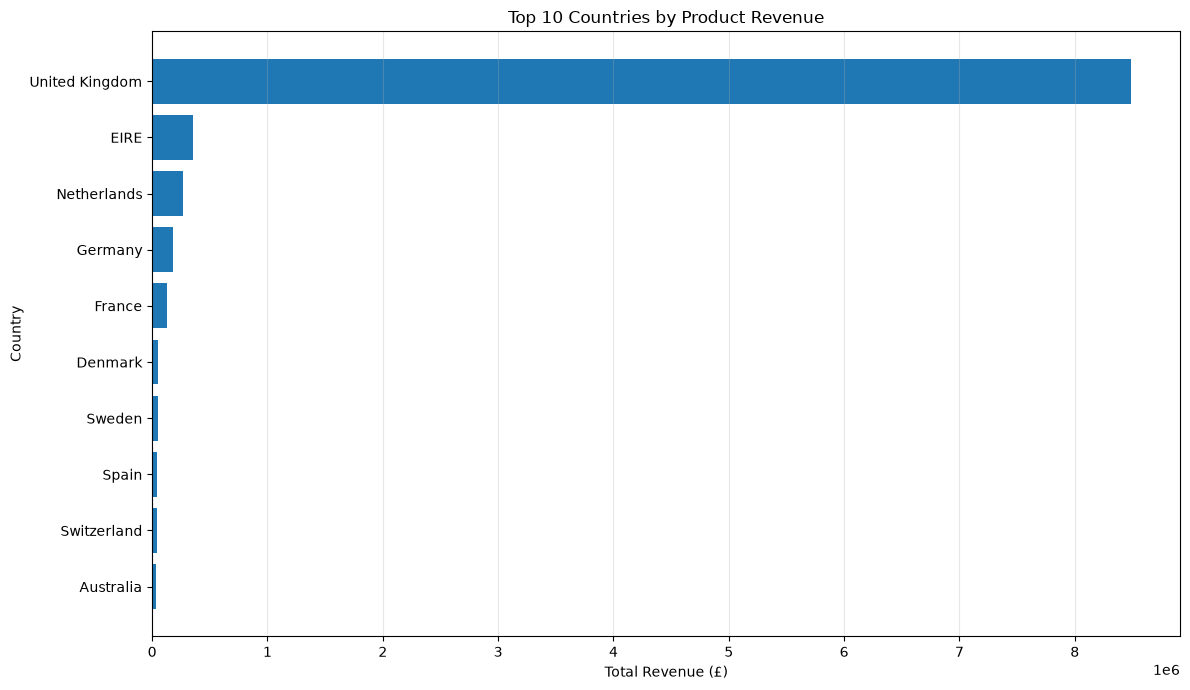

In [37]:
# Top 10 Countries by Product Revenue

top_countries = country_revenue.head(10)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_countries["country"],
    top_countries["total_revenue"]
)

ax.invert_yaxis()

ax.set_title("Top 10 Countries by Product Revenue")
ax.set_xlabel("Total Revenue (£)")
ax.set_ylabel("Country")

ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

In [38]:
fig.savefig(
    images_dir / "top_10_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

print("Country revenue chart saved successfully!")

Country revenue chart saved successfully!


## 7. Customer Analysis

This section analyzes customer purchasing behavior,
identifies top customers by revenue, and evaluates
order frequency and average order value.

In [40]:
# Prepare data for customer analysis

customers_df = analysis_df[
    (analysis_df["transaction_type"] == "Product")
    & (analysis_df["customer_id"].notna())
].copy()

print("Rows with valid customer IDs:", len(customers_df))

print(
    "Unique customers:",
    customers_df["customer_id"].nunique()
)

Rows with valid customer IDs: 406321
Unique customers: 4285


In [41]:
# Top 10 customers by revenue

top_customers = (
    customers_df
    .groupby("customer_id")
    .agg(
        total_revenue=("revenue", "sum"),
        total_orders=("invoice", "nunique")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

display(top_customers)

,customer_id,total_revenue,total_orders
4156,18102.0,349164.35,89
1620,14646.0,247613.50,73
1256,14156.0,186849.00,91
1820,14911.0,140378.89,183
928,13694.0,131443.19,94
3718,17511.0,84541.17,31
1931,15061.0,83282.93,86
3103,16684.0,80489.21,27
3152,16754.0,65500.07,29
496,13089.0,57912.03,109


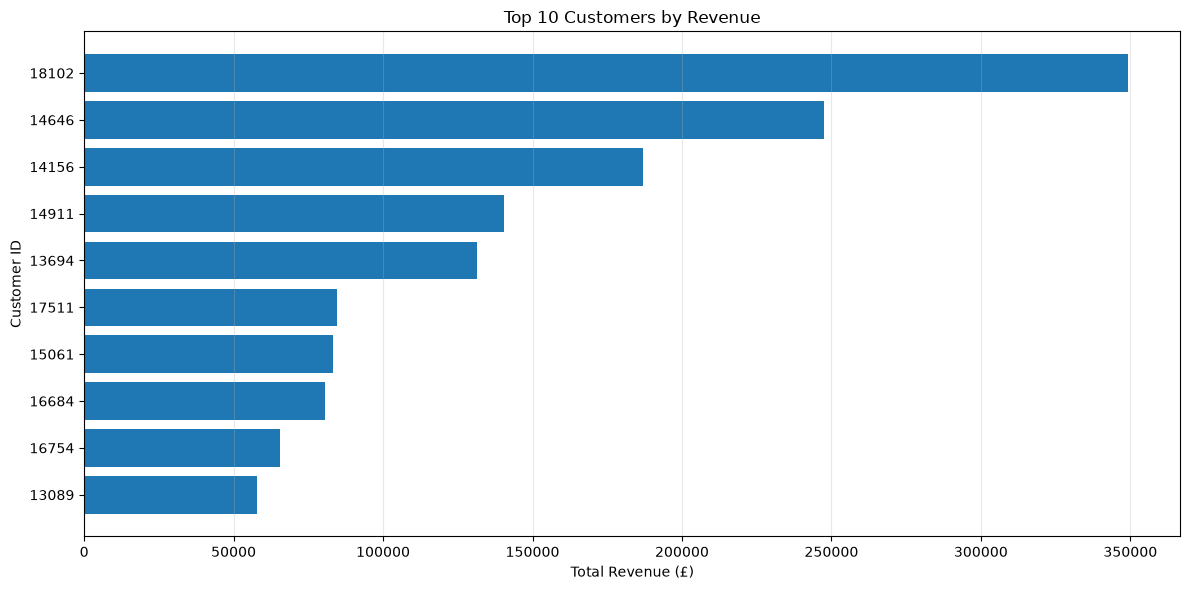

In [42]:
# Top 10 Customers by Revenue - Visualization

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    top_customers["customer_id"].astype(int).astype(str),
    top_customers["total_revenue"]
)

ax.set_title("Top 10 Customers by Revenue")
ax.set_xlabel("Total Revenue (£)")
ax.set_ylabel("Customer ID")

ax.invert_yaxis()

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# Save customer revenue chart

fig.savefig(
    images_dir / "top_10_customers_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

print("Customer revenue chart saved successfully!")

Customer revenue chart saved successfully!


In [44]:
# Calculate Average Order Value for top customers

top_customers["avg_order_value"] = (
    top_customers["total_revenue"] /
    top_customers["total_orders"]
).round(2)

display(top_customers)

,customer_id,total_revenue,total_orders,avg_order_value
4156,18102.0,349164.35,89,3923.19
1620,14646.0,247613.50,73,3391.97
1256,14156.0,186849.00,91,2053.29
1820,14911.0,140378.89,183,767.10
928,13694.0,131443.19,94,1398.33
3718,17511.0,84541.17,31,2727.13
1931,15061.0,83282.93,86,968.41
3103,16684.0,80489.21,27,2981.08
3152,16754.0,65500.07,29,2258.62
496,13089.0,57912.03,109,531.30


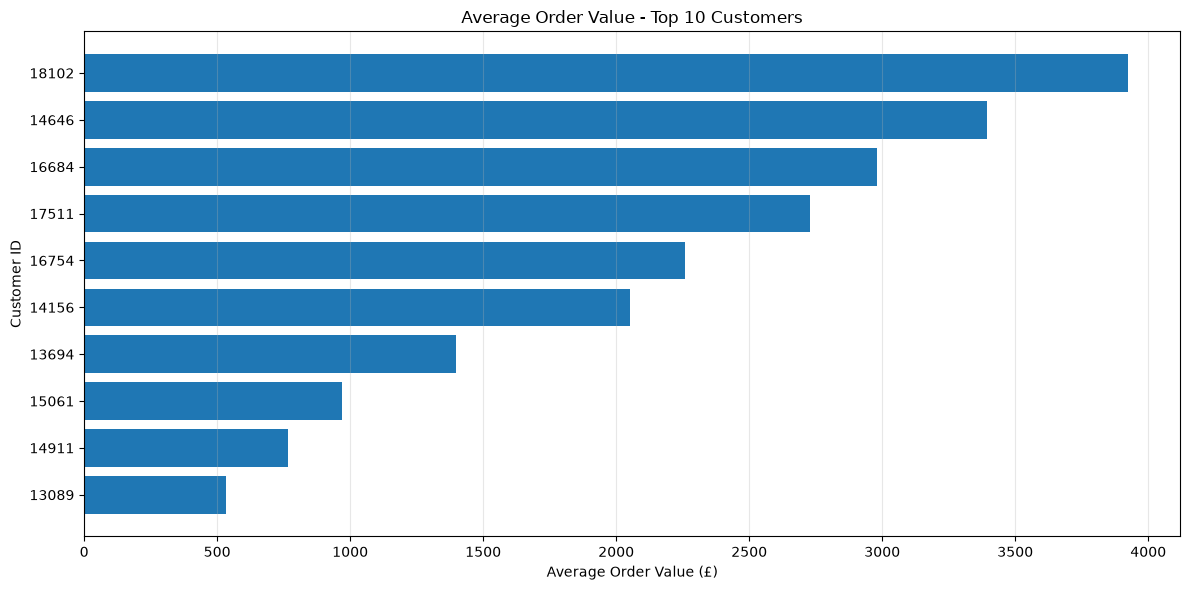

In [45]:
# Average Order Value by Top 10 Customers

aov_customers = top_customers.sort_values(
    "avg_order_value",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    aov_customers["customer_id"].astype(int).astype(str),
    aov_customers["avg_order_value"]
)

ax.set_title("Average Order Value - Top 10 Customers")
ax.set_xlabel("Average Order Value (£)")
ax.set_ylabel("Customer ID")

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
aov_customers = top_customers.sort_values(
    "avg_order_value",
    ascending=False
)

In [48]:
# Save AOV chart

fig.savefig(
    images_dir / "top_10_customers_aov.png",
    dpi=300,
    bbox_inches="tight"
)

print("Customer AOV chart saved successfully!")

Customer AOV chart saved successfully!


### 7.8 Customer Revenue Concentration

This analysis measures the percentage of identifiable
customer revenue generated by the top 10 customers.

It helps evaluate customer concentration and potential
business dependency on high-value customers.

In [49]:
# Customer Revenue Concentration Analysis

# Total revenue from identifiable customers
total_customer_revenue = customers_df["revenue"].sum()

# Revenue generated by the top 10 customers
top_10_revenue = top_customers["total_revenue"].sum()

# Calculate revenue concentration
concentration_percentage = (
    top_10_revenue / total_customer_revenue
) * 100

print(
    "Total identifiable customer revenue:",
    round(total_customer_revenue, 2)
)

print(
    "Top 10 customer revenue:",
    round(top_10_revenue, 2)
)

print(
    "Top 10 revenue concentration:",
    round(concentration_percentage, 2), "%"
)

Total identifiable customer revenue: 8673624.09
Top 10 customer revenue: 1427174.34
Top 10 revenue concentration: 16.45 %


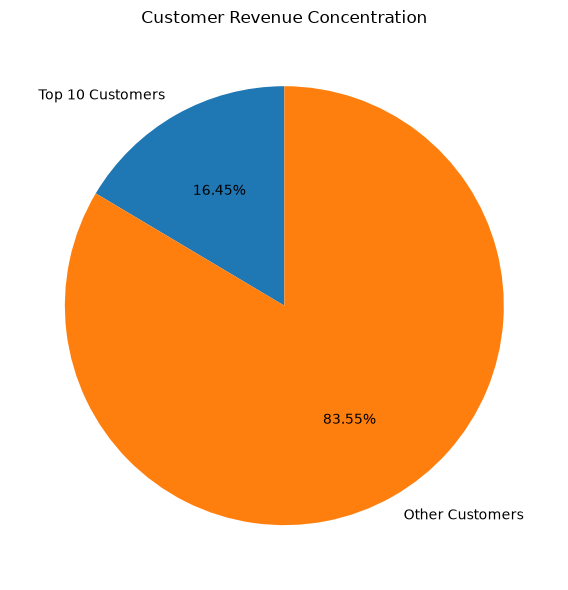

In [50]:
# Customer Revenue Concentration Visualization

labels = ["Top 10 Customers", "Other Customers"]

values = [
    top_10_revenue,
    total_customer_revenue - top_10_revenue
]

fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)

ax.set_title("Customer Revenue Concentration")

plt.tight_layout()
plt.show()

In [51]:
# Save Customer Revenue Concentration Chart

fig.savefig(
    images_dir / "customer_revenue_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

print("Customer concentration chart saved successfully!")

Customer concentration chart saved successfully!


## 8. Final Data Validation

This section validates the processed dataset before
using it for business intelligence reporting in Power BI.

In [52]:
# Final dataset validation

print("Dataset dimensions:")
print(analysis_df.shape)

print("\nColumn names:")
print(analysis_df.columns.tolist())

print("\nMissing values:")
print(analysis_df.isnull().sum())

print("\nTransaction types:")
print(analysis_df["transaction_type"].value_counts())

print("\nTotal revenue:")
print(round(analysis_df["revenue"].sum(), 2))

print("\nProduct revenue:")
print(
    round(
        analysis_df.loc[
            analysis_df["transaction_type"] == "Product",
            "revenue"
        ].sum(),
        2
    )
)

Dataset dimensions:
(511565, 10)

Column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'revenue', 'transaction_type']

Missing values:
invoice                  0
stock_code               0
description              0
quantity                 0
invoice_date             0
price                    0
customer_id         103901
country                  0
revenue                  0
transaction_type         0
dtype: int64

Transaction types:
transaction_type
Product        509317
Non-product      2248
Name: count, dtype: int64

Total revenue:
10305892.02

Product revenue:
9840118.11


In [53]:
# Check data types

print("Dataset data types:")
print(analysis_df.dtypes)

print("\nInvoice date type:")
print(analysis_df["invoice_date"].dtype)

print("\nSample invoice dates:")
print(analysis_df["invoice_date"].head())

Dataset data types:
invoice                     object
stock_code                  object
description                 object
quantity                     int64
invoice_date        datetime64[us]
price                      float64
customer_id                float64
country                        str
revenue                    float64
transaction_type               str
dtype: object

Invoice date type:
datetime64[us]

Sample invoice dates:
0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
Name: invoice_date, dtype: datetime64[us]


In [54]:
# Validate revenue calculations

calculated_revenue = (
    analysis_df["quantity"] * analysis_df["price"]
)

revenue_difference = (
    analysis_df["revenue"] - calculated_revenue
).abs()

incorrect_rows = (revenue_difference > 0.0001).sum()

print("Total rows:", len(analysis_df))
print("Rows with incorrect revenue:", incorrect_rows)
print("Maximum revenue difference:", revenue_difference.max())

Total rows: 511565
Rows with incorrect revenue: 0
Maximum revenue difference: 0.0


In [55]:
from pathlib import Path
import pandas as pd

# Locate the processed dataset
csv_path = Path("../data/processed/sales_analysis.csv")

# Load the saved dataset
saved_df = pd.read_csv(csv_path)

print("Saved dataset rows:", len(saved_df))
print("Saved dataset columns:", len(saved_df.columns))

print("\nColumn names:")
print(saved_df.columns.tolist())

print("\nTransaction types:")
print(saved_df["transaction_type"].value_counts())

print("\nTotal revenue:")
print(round(saved_df["revenue"].sum(), 2))

Saved dataset rows: 511565
Saved dataset columns: 10

Column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country', 'revenue', 'transaction_type']

Transaction types:
transaction_type
Product        509317
Non-product      2248
Name: count, dtype: int64

Total revenue:
10305892.02
